# Funciones de pérdida, optimización e hiperparámetros

Entrenar un modelo es resolver un problema de optimización: encontrar los parámetros $\theta$ que minimizan una función de pérdida sobre los datos de entrenamiento. Los hiperparámetros, en cambio, son decisiones que se toman antes del entrenamiento (la complejidad del modelo, la penalización, la tasa de aprendizaje) y que se eligen comparando el desempeño en validación {cite}`goodfellow2016,raschka2017`.

## Pérdida y costo

La función de pérdida mide el error en una observación; la función de costo la promedia sobre todas, a veces con un término de regularización; el optimizador es el algoritmo que busca su mínimo. En regresión, la pérdida cuadrática (L2) lleva a los mínimos cuadrados y es sensible a los atípicos; la absoluta (L1) es robusta pero no es derivable en cero; la de Huber combina ambas. En clasificación se usa la entropía cruzada o pérdida logarítmica, $-[y \log p + (1-y)\log(1-p)]$, que penaliza mucho las predicciones seguras y equivocadas.

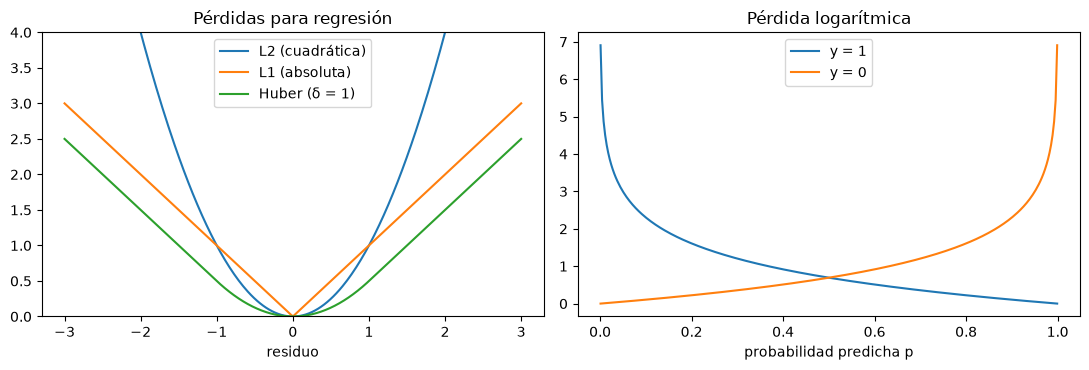

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(5)

e = np.linspace(-3, 3, 300)
huber = np.where(np.abs(e) <= 1, 0.5 * e**2, np.abs(e) - 0.5)
p = np.linspace(0.001, 0.999, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(e, e**2, label='L2 (cuadrática)'); ax[0].plot(e, np.abs(e), label='L1 (absoluta)'); ax[0].plot(e, huber, label='Huber (δ = 1)')
ax[0].set_xlabel('residuo'); ax[0].set_ylim(0, 4); ax[0].legend(); ax[0].set_title('Pérdidas para regresión')
ax[1].plot(p, -np.log(p), label='y = 1'); ax[1].plot(p, -np.log(1 - p), label='y = 0')
ax[1].set_xlabel('probabilidad predicha p'); ax[1].legend(); ax[1].set_title('Pérdida logarítmica')
plt.tight_layout(); plt.show()

## La ecuación normal

Para la regresión lineal con pérdida cuadrática hay una solución analítica, la ecuación normal: $\hat\theta = (X^T X)^{-1} X^T y$. Se resuelve en un solo paso, sin iterar. Su problema es el costo cuando hay muchas variables (invertir una matriz de $p \times p$ crece como $p^3$) o muchas observaciones (la matriz no cabe en memoria), y que no existe para la mayoría de los modelos.

## Descenso por gradiente

El descenso por gradiente es el optimizador general. Parte de unos parámetros iniciales y avanza repetidamente en la dirección contraria al gradiente de la función de costo, $\theta \leftarrow \theta - \alpha \nabla J(\theta)$, hasta llegar a un mínimo. La tasa de aprendizaje $\alpha$ fija el tamaño de los pasos: si es muy pequeña, el algoritmo tarda mucho; si es muy grande, oscila o diverge. En el descenso por gradiente estocástico y por minilotes, el gradiente se calcula con una observación o un pequeño grupo en cada paso, lo que lo hace viable con millones de datos y es la base del entrenamiento de las redes neuronales. Las funciones convexas, como la de la regresión lineal o logística, tienen un único mínimo; las no convexas, como las de las redes neuronales, pueden tener mínimos locales.

La celda siguiente ajusta una regresión lineal con la ecuación normal y con descenso por gradiente, y dibuja la trayectoria del descenso sobre la superficie de costo para tres tasas de aprendizaje.

Ecuación normal: intercepto 2.356, pendiente 0.750


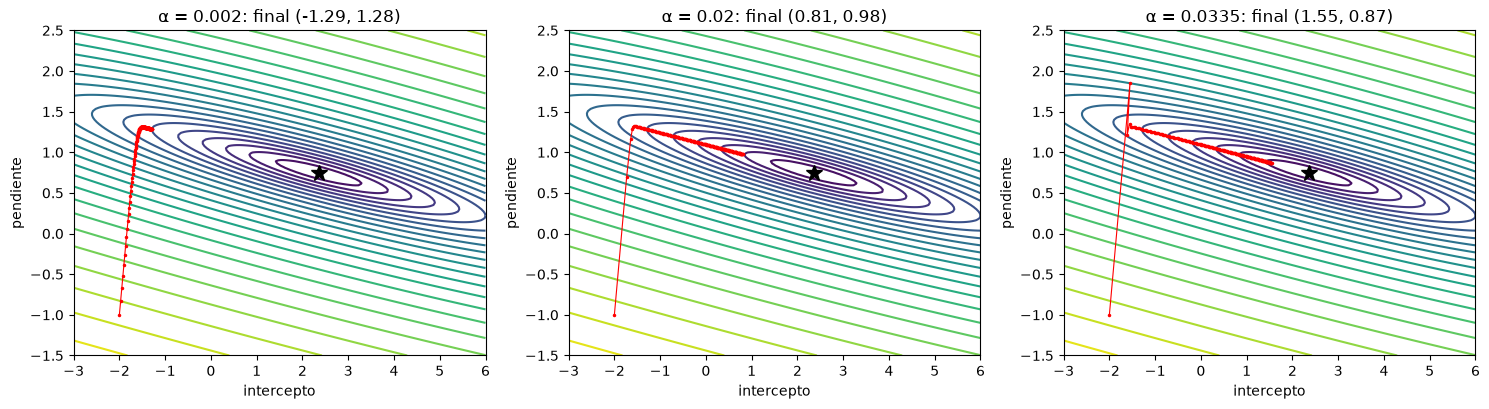

In [2]:
n = 100
x = rng.uniform(0, 10, n); y = 2.0 + 0.8 * x + rng.normal(0, 1, n)
Xd = np.column_stack([np.ones(n), x])
theta_ne = np.linalg.solve(Xd.T @ Xd, Xd.T @ y)
print(f'Ecuación normal: intercepto {theta_ne[0]:.3f}, pendiente {theta_ne[1]:.3f}')

def costo(t0, t1):
    return np.mean((y[:, None, None] - t0 - t1 * x[:, None, None])**2, axis=0) / 2

def descenso(alfa, pasos=200):
    th = np.array([-2.0, -1.0]); tray = [th.copy()]
    for _ in range(pasos):
        grad = Xd.T @ (Xd @ th - y) / n
        th = th - alfa * grad; tray.append(th.copy())
    return np.array(tray)

T0, T1 = np.meshgrid(np.linspace(-3, 6, 150), np.linspace(-1.5, 2.5, 150))
J = costo(T0, T1)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, alfa in zip(axs, [0.002, 0.02, 0.0335]):
    tr = descenso(alfa)
    ax.contour(T0, T1, np.log(J), 25, cmap='viridis')
    ax.plot(tr[:, 0], tr[:, 1], 'r.-', ms=3, lw=0.8); ax.plot(*theta_ne, 'k*', ms=12)
    ax.set_xlim(-3, 6); ax.set_ylim(-1.5, 2.5); ax.set_xlabel('intercepto'); ax.set_ylabel('pendiente')
    ax.set_title(f'α = {alfa}: final ({tr[-1, 0]:.2f}, {tr[-1, 1]:.2f})')
plt.tight_layout(); plt.show()

Con una tasa pequeña el algoritmo avanza muy lento y no llega al mínimo en 200 pasos; con una tasa adecuada llega; con una tasa cercana al límite de estabilidad oscila de un lado al otro del valle. Estandarizar las variables hace la superficie de costo más redonda y acelera mucho la convergencia, otra razón para escalar los datos.

## Hiperparámetros y su búsqueda

Los hiperparámetros se eligen evaluando con validación cruzada distintas combinaciones de valores. La búsqueda en malla (grid search) prueba todas las combinaciones de una lista de valores; es exhaustiva pero su costo crece exponencialmente con el número de hiperparámetros. La búsqueda aleatoria (random search) prueba combinaciones al azar dentro de unos rangos y, con el mismo presupuesto, suele encontrar soluciones tan buenas o mejores, porque explora más valores de los hiperparámetros que de verdad importan. Hay métodos más eficientes, como la optimización bayesiana, que usa los resultados anteriores para decidir qué probar después. La celda siguiente compara la malla y la búsqueda aleatoria para un modelo de boosting de gradiente (capítulo 15).

Malla (27 combinaciones):     AUC 0.8516 con {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 150}
Aleatoria (27 combinaciones): AUC 0.8519 con {'learning_rate': 0.045, 'max_depth': 1, 'n_estimators': 367}


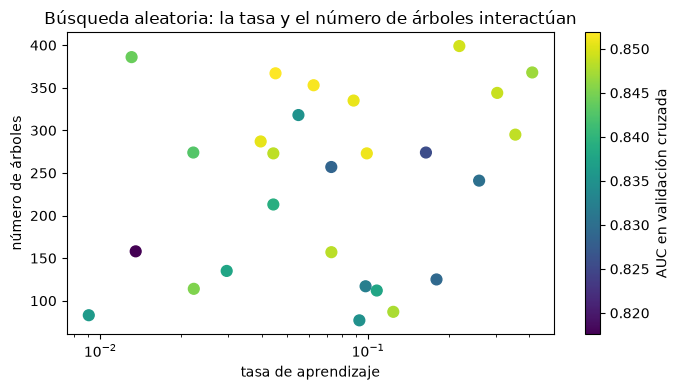

In [3]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint

m = 2000
pend = rng.gamma(4, 6, m); dist = rng.exponential(250, m); lluv = rng.normal(2500, 500, m); curv = rng.normal(0, 1, m)
eta = -6 + 0.12 * pend - 0.004 * dist + 0.0012 * lluv - 0.5 * curv * (pend > 25)
yb = (rng.random(m) < 1 / (1 + np.exp(-eta))).astype(int)
Xb = np.column_stack([pend, dist, lluv, curv])
cv = StratifiedKFold(4, shuffle=True, random_state=0)
malla = GridSearchCV(GradientBoostingClassifier(random_state=0),
                     {'learning_rate': [0.01, 0.1, 0.3], 'max_depth': [1, 3, 5], 'n_estimators': [50, 150, 300]},
                     cv=cv, scoring='roc_auc', n_jobs=-1).fit(Xb, yb)
aleat = RandomizedSearchCV(GradientBoostingClassifier(random_state=0),
                           {'learning_rate': loguniform(0.005, 0.5), 'max_depth': randint(1, 6), 'n_estimators': randint(30, 400)},
                           n_iter=27, cv=cv, scoring='roc_auc', random_state=0, n_jobs=-1).fit(Xb, yb)
print(f'Malla (27 combinaciones):     AUC {malla.best_score_:.4f} con {malla.best_params_}')
mejores = {k: (round(float(v), 3) if isinstance(v, float) else int(v)) for k, v in aleat.best_params_.items()}
print(f'Aleatoria (27 combinaciones): AUC {aleat.best_score_:.4f} con {mejores}')

res = aleat.cv_results_
fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(res['param_learning_rate'].astype(float), res['param_n_estimators'].astype(float), c=res['mean_test_score'], cmap='viridis', s=60)
ax.set_xscale('log'); ax.set_xlabel('tasa de aprendizaje'); ax.set_ylabel('número de árboles')
fig.colorbar(sc, label='AUC en validación cruzada'); ax.set_title('Búsqueda aleatoria: la tasa y el número de árboles interactúan')
plt.tight_layout(); plt.show()

La gráfica muestra una interacción típica: tasas de aprendizaje pequeñas necesitan muchos árboles y tasas grandes, pocos. Por eso conviene buscar los hiperparámetros juntos y no uno por uno. Recuerde que el mejor puntaje de la búsqueda es optimista; la evaluación honesta requiere un conjunto de prueba independiente o validación anidada (capítulo {doc}`06_Validacion`).

## Para profundizar

El capítulo 4 de {cite}`goodfellow2016` trata la optimización numérica y el 8, el entrenamiento de modelos profundos. El capítulo 6 de {cite}`raschka2017` presenta la búsqueda de hiperparámetros con `scikit-learn`. Los notebooks 09 y 15_LR del curso muestran la búsqueda de hiperparámetros y el descenso por gradiente.